In [5]:
# Instala dependencias en el kernel ACTIVO del notebook
%pip install -q langchain-community langchain-text-splitters langchain-google-genai faiss-cpu pypdf python-dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
# Preparacion del entorno del notebook
import os
import logging
from dotenv import load_dotenv

logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

# Carga ambas rutas habituales de variables de entorno
load_dotenv(dotenv_path='geminiapi.env')
load_dotenv(dotenv_path='.env')

# Acepta tambien GEMINI_API_KEY y la normaliza a GOOGLE_API_KEY
if not os.getenv('GOOGLE_API_KEY') and os.getenv('GEMINI_API_KEY'):
    os.environ['GOOGLE_API_KEY'] = os.getenv('GEMINI_API_KEY', '')

if not os.getenv('GOOGLE_API_KEY'):
    raise ValueError('Falta GOOGLE_API_KEY. Define la clave en geminiapi.env o .env.')

# Verificacion rapida de imports
import langchain_community, langchain_text_splitters, langchain_google_genai
print('Imports OK y API key cargada')

Imports OK y API key cargada


In [7]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_community.vectorstores import FAISS

# 1. Cargar el documento PDF
loader = PyPDFLoader("data/TENERIFE.pdf")
docs = loader.load()

# 2. Dividir en fragmentos (chunks)
text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
chunks = text_splitter.split_documents(docs)

# 3. Generar embeddings y guardar en el Vector Store (FAISS)
embeddings = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")
vector_store = FAISS.from_documents(chunks, embeddings)

# 4. Configurar el retriever
retriever = vector_store.as_retriever(search_kwargs={"k": 3})

# Función auxiliar para inyectar la página en el prompt y forzar la citación
def format_docs(docs):
    formatted = []
    for doc in docs:
        page = doc.metadata.get('page', 'Desconocida')
        formatted.append(f"--- Fuente: Página {page} ---\n{doc.page_content}")
    return "\n\n".join(formatted)

2026-11-04 22:24:34,497 - INFO - HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-embedding-001:batchEmbedContents "HTTP/1.1 200 OK"
2026-11-04 22:24:34,664 - INFO - Loading faiss with AVX2 support.
2026-11-04 22:24:34,665 - INFO - Could not load library with AVX2 support due to:
ModuleNotFoundError("No module named 'faiss.swigfaiss_avx2'")
2026-11-04 22:24:34,666 - INFO - Loading faiss.
2026-11-04 22:24:34,710 - INFO - Successfully loaded faiss.


In [8]:
from langchain_core.tools import tool

@tool
def get_weather(fecha: str) -> str:
    """
    Devuelve la predicción del tiempo simulada para una fecha específica.
    Args:
        fecha: La fecha de consulta en formato YYYY-MM-DD.
    """
    logging.info(f"Ejecutando get_weather para la fecha: {fecha}")
    try:
        # Lógica simulada con gestión de errores básica
        if not fecha:
            raise ValueError("Fecha no proporcionada.")
        return f"Predicción para el {fecha}: 24ºC, mayormente soleado con brisa ligera."
    except Exception as e:
        logging.error(f"Error en get_weather: {e}")
        return "Lo siento, hubo un error al consultar el servicio meteorológico."

In [9]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import SystemMessage, HumanMessage, ToolMessage

# Modelo compatible con tu API key
llm = ChatGoogleGenerativeAI(
    model="gemini-flash-latest",
    temperature=0.3,
    max_tokens=500,
    top_p=0.9
)

llm_with_tools = llm.bind_tools([get_weather])

historial = [
    SystemMessage(content=(
        "Eres un asistente turistico experto en Tenerife. "
        "Utiliza la informacion del contexto para responder. "
        "Si usas informacion del contexto, cita SIEMPRE el numero de pagina al final de tu respuesta."
    ))
]

def asistente_turistico(pregunta_usuario: str):
    print(f"\nUsuario: {pregunta_usuario}")
    docs_recuperados = retriever.invoke(pregunta_usuario)
    contexto_texto = format_docs(docs_recuperados)
    prompt_completo = f"Contexto recuperado:\n{contexto_texto}\n\nPregunta: {pregunta_usuario}"
    historial.append(HumanMessage(content=prompt_completo))

    respuesta = llm_with_tools.invoke(historial)

    if respuesta.tool_calls:
        historial.append(respuesta)
        for tool_call in respuesta.tool_calls:
            if tool_call["name"] == "get_weather":
                args = tool_call["args"]
                resultado = get_weather.invoke(args)
                tool_msg = ToolMessage(content=resultado, tool_call_id=tool_call["id"])
                historial.append(tool_msg)
        respuesta_final = llm_with_tools.invoke(historial)
        historial.append(respuesta_final)
        print(f"Asistente: {respuesta_final.content}")
    else:
        historial.append(respuesta)
        print(f"Asistente: {respuesta.content}")

    while len(historial) > 7:
        historial.pop(1)

In [10]:
# Prueba 1: Consulta RAG pura
asistente_turistico("¿Qué me recomiendas visitar en el Norte de Tenerife?")

# Prueba 2: Pregunta de seguimiento (demuestra diálogo multiturno)
asistente_turistico("De los sitios que acabas de mencionar, ¿cuál es el pueblo más bonito?")

# Prueba 3: Consulta que dispara el Function Calling
asistente_turistico("¿Qué tiempo va a hacer allí el 2026-11-13?")


Usuario: ¿Qué me recomiendas visitar en el Norte de Tenerife?


2026-11-04 22:24:49,209 - INFO - HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-embedding-001:batchEmbedContents "HTTP/1.1 200 OK"
2026-11-04 22:24:54,584 - INFO - HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-flash-latest:generateContent "HTTP/1.1 200 OK"


Asistente: [{'type': 'text', 'text': 'En la zona norte de Tenerife se recomiendan varios lugares destacados para visitar y disfrutar:\n\n### 1. Santa Cruz de Tenerife (la capital)\nUna buena ruta sugerida es:\n* Aparcar en el aparcamiento del **Parque Marítimo César Manrique** (un conjunto de piscinas naturales', 'extras': {'signature': 'Eu0NCuoNAWkUfROCkyE+7DolY27V2T5YHljjJ9jgYrPr2XMr1eP/twuT0L3OmbUCBtlwQqR7We3LhfsusPR8JtAnux2gsVy2w5Qdilebv7AUN9U5+0IvKm4NGgBb9UEb0tui9XOliIwCrAXuSEgRJgQeFqulWQaGWfi9K9I4fQplsFz1nR2xm0ENfxIIUpWhy7n5T36fNlP1dzqhxApPOtjNsTJv0Nn+3csdtcjd88tJtYt5MjCLScylrPZ0rG+zmSNQl7YYcpfZ0WlPdkqtGNz7sjEzqIKjeQ9shUq7kujJ+TDsB6kTwrP7lQmVU+Ey8g+1zrYGGSxQFpnX2pFCamHJRxyOIjxuRTigJaYL89KudRubjpz1Yartanl8vqN3Dr7cboQefZkTRmYKOY3o01qN4/JQvzDv1Y1/XwZZ/+zn3NcZsXAIlD87eX7mf/EO9TEi1PaVb7IcvOc3M9Rm187i4EWd/3eQK3Rwiuf36osjFxKtxyX/3f8xw6cJUJ0ivSy6aoXCV4ccwO5XWm2mP9RZDJbzyD9cauhtKzYu4o68e8KJWcdGrgyIwJv7Sb+VDp68UoGvZSwqXrEKYqDzvmLGYM5uyMZYvV3XdaHrct5xeIEMfDMBQ5ANVm9atmmu6ILVUku2PLjU2Gz12sDT

2026-11-04 22:24:54,985 - INFO - HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-embedding-001:batchEmbedContents "HTTP/1.1 200 OK"
2026-11-04 22:24:57,915 - INFO - HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-flash-latest:generateContent "HTTP/1.1 200 OK"


Asistente: [{'type': 'text', 'text': 'El pueblo más bonito es **La Orotava**, al que se describe como «el pueblo más bonito y maravilloso del mundo (no es porque yo sea de allí)».\n\n---\n**Fuente consultada:** Página 7.', 'extras': {'signature': 'ErYGCrMGAWkUfRM4yyOYSEhfGHBF/o85xRPURkImsix3+uaRXQyDZFmVNcWxGErveLLD0sQ7bplpmwt9gE/53OeooRKUwazruFYafkDGm+RuJXvtqIFBSgzn20iRy716ky5lg1fqqNlqkegMWuUwVYLYZmhoa1HIT7nax2l9zfU4Lh+XMoTA7Db51kHl5kKGcQFq0O2VScFJpGtQ8xjylT+lxunf1ndLw4rBDLAfVxEs/yI46tA61rgmOPuGqkIDaDiYZlnt2vZz7wz0IMHZEGu5r9FnOEEHPTTLsLjfXrcoAqL6B5Q27aiT9g8z6GkHqWWAGTrPGnjm5qCi+7vT1l01coYoBjh0Vk43aHcf0F8H2d7Xq9X/f3gr512gzXSB5COBP1jB0//zO3csq0YFfy4iREGEA6h63VmeezrUzt9ZBRYSKYnjoE9DjJ9AqJW2hMeHtcc+bPBROo9fYyaYr7/0t2IzulcSCYkhdOzLTTHeAjrlPCdjCYI3dbiiSM1MYwbgZvfbKv+NHzSz2wVD9pN37DKqMqcbdQt5ibiwtiM7HZ3hnOjLPVYVmNEAKY2roQHYVQXdRPycnQsuU/zNGDFB4i0hTJPgmO+Fj7DWtJgHR5JPH6iMvG9hF0hH+ih8bY8t7S7m2KcPfQAZ5MlN2rAMX91WR+pTV5Q7Ieb53ATOF1Mmm69aKsBxyo0rssMfEYAZP/oUDh5as9E1LiKCKOf3Vk7Xom8oj0JMeJNqt5Fe0JlL

2026-11-04 22:24:58,168 - INFO - HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-embedding-001:batchEmbedContents "HTTP/1.1 200 OK"
2026-11-04 22:25:01,224 - INFO - HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-flash-latest:generateContent "HTTP/1.1 200 OK"
2026-11-04 22:25:01,231 - INFO - Ejecutando get_weather para la fecha: 2026-11-13
2026-11-04 22:25:04,234 - INFO - HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-flash-latest:generateContent "HTTP/1.1 200 OK"


Asistente: [{'type': 'text', 'text': 'Para el 13 de noviembre de 2026 se prevé un día mayormente soleado con brisa ligera y una temperatura de 24 ºC.', 'extras': {'signature': 'EtgECtUEAWkUfRMRDvnTbZLSILbmd3tcB9QPlRlF+L5VgKNTjrEKy2mUqkvbt91z9+VCdsLSryMLm84aOcr9jqidtEzNYkP/Dv+b4Cli4VYdzk68cNn8wGgSj//gui4yU7fiwgLi6BriULSmoJcfUbSncsiEOOZKIBjwONn0zd/W6D/GtxwvtTQNeYPsTdaxh2fCxRCttG/F7kjW3+BREZRkv0w9FuIPYxyyYEs5WOEDanVEpyL6rIiImk0N9EW3NfDOGpMZfdYeUHHz/vo63W5V9uPbRwJEDNvC180w1tk0+e7kQcZNWsUomC8pGAIGpdanyS4qvPW/XhJGj2Ud1zziI+n8T+OaBisMEtAtFDI/nxqKAC+EgyiIyfMKVbAu5PHzI0JPS1GzwLT5hEZiBszLGpmhTsE3Qq53dBVpZY7RwXYEeuKsXnLfpqDE1fLA4U9kPAtBnBM3z5tRbk2iQWNntEAPfrPvsC2rBA2pX5v0DNUXI3mA4E1+WkpZqEpoi3Len6ChjTDhOrGs99lOrbkbby7L9OKegZqb6yinJeA+HqVwLcZY58mfdfj8tviQAfSB/TEE/YBHFc4oRYO5YimejCtsXfsRBBDaKQTvqraO7zO79YePUHEtgavKkQ/y/E0GV9M89enVVwL0CMD3BM097U//RAEW7mEXZtON+oxsj9OHluqrhus62gkDYvkh6qoO086cmqDL5xH9UJ48IcYIEm3HRtViQAhyJCfT40Y3oG4Cdrm8ZHjDaHGbv/xZG3hUKSbr5WabSrb0yrZF8m85nlz7rpjcwy1r'}}]


--- Iniciando Evaluación de Rendimiento ---

[Evaluando Q1]: ¿Cuál es la capital de la isla?

Usuario: ¿Cuál es la capital de la isla?


2026-11-04 22:25:05,040 - INFO - HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-embedding-001:batchEmbedContents "HTTP/1.1 200 OK"
2026-11-04 22:25:07,203 - INFO - HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-flash-latest:generateContent "HTTP/1.1 200 OK"


Asistente: [{'type': 'text', 'text': 'La capital de la isla es **Santa Cruz de Tenerife**.\n\n---\n**Fuente consultada:** Página 0.', 'extras': {'signature': 'EsQDCsEDAWkUfRNtYogHMezAhfyNvSmDwQDhNYZ4uhCj4uAxBAMevo24tcFd6llvrm+ZE6Fv2fAAJ8NoO2ZQA7JwxTBfFQctGbE00yHOInbiog/zI3nGB7svDttjLeCRbvZad4wuqj4vrK8e+qlcew4ykbyM0rujFp+YT6k3ibHrRLuyVaCWCRJ7108Tyw6WZnIDjDPrLFqTkMrpszywYxcN6zsRCROaxw1Dxu59jVYEoJ+2AJPjkWJsSiBL25IL006NqjX898J60/BZ+GD8LOYGROvUnNcoId3Iw/D1Ns3ucaM9xTiwSLgqdzpBaKkOAUN6NuqNFAbkKFxXjcgjm1pacXoKdiJ7/VolbTma189TvfGUInngkLGSgiWAH9+1baEXibn67ZoUMK76ZFMUwPyIWOSO7DVznLaktRdnMfuCuFF1dVfnLPYv0uZVneGc2fjZmqTJZZ2GXq9c+lW89F81JDE+zwfxIdF2+CRYF07eQ6NW88AXnyOjH0BFHGEx/1VUWBHUvB3/j9+4dyfrj6dxKJM2/LZ5pZKN+2Kme04T4VbeE8ote4TAu84vxGgXC0O683wSLrJdx2ccOu8KERC7G8HMUdg='}}]
-> Tiempo de latencia: 2.58 segundos

[Evaluando Q2]: Dime algunas playas recomendadas en la zona norte.

Usuario: Dime algunas playas recomendadas en la zona norte.


2026-11-04 22:25:07,485 - INFO - HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-embedding-001:batchEmbedContents "HTTP/1.1 200 OK"
2026-11-04 22:25:11,462 - INFO - HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-flash-latest:generateContent "HTTP/1.1 200 OK"


Asistente: [{'type': 'text', 'text': 'En la zona norte se recomiendan las siguientes playas:\n\n* **Playa de Las Teresitas** (en el entorno de Santa Cruz de Tenerife).\n* **Playa de Los Patos** y **Playa del Ancón** (ten en cuenta que para llegar a estas hay que caminar un rato, algunas tienen difícil acceso como la de Los Patos, se debe ir con marea baja y tener mucho respeto por las corrientes).\n* **Playa Martiánez** (en Puerto de la Cruz).\n\n---\n**Fuente consultada:** Páginas 0, 9 y 10.', 'extras': {'signature': 'EukFCuYFAWkUfRMEmh9AmiQJ6WXBImWAPlLYfnOKmgxAGfHWLYh+ApT5sEwIMB1WBl6Zphifk7v9MZvVQFRlYAnC8BRn94uo4Ir9UFSQiH5Wh8bsSrAHZpCYgdGYHphmt169Esjm420P5V/CJChPJVaW0JT3+vAQ2aUSqaBjsnOmLRll+5tl7tmg5oeV3E+3KReVBRzAbZUNYJKRPApp4bZDWfb7jDJDYEHn8ABJqTzp1CNS97Y7vmnMa3+OTzUQjHPz2osUfiD0fy+kzMuQ5PrEkNpGAbCXdowskkUPaFZg38s0A74mPQSBpA1IWH3nd0K3EHLYnvkpHjB6GimA1BL6FcWncj+cyD+YK3JqfX4AgSokn1rU7Ii3orK3ucyeXrNn+UoVyP45pJ0zxX0AMkg8rYg4Y+ixCj5mRy6156zZTT+qlGQlRmIEIAP7ea7yzNIOm+Ab79xbbwWEloDQ5nLsVS6

2026-11-04 22:25:11,756 - INFO - HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-embedding-001:batchEmbedContents "HTTP/1.1 200 OK"
2026-11-04 22:25:14,451 - INFO - HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-flash-latest:generateContent "HTTP/1.1 200 OK"
2026-11-04 22:25:14,463 - INFO - Ejecutando get_weather para la fecha: 2026-11-13
2026-11-04 22:25:17,608 - INFO - HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-flash-latest:generateContent "HTTP/1.1 200 OK"


Asistente: [{'type': 'text', 'text': 'Para el 13 de noviembre de 2026 se pronostica una temperatura de 24 ºC, con un día mayormente soleado y brisa ligera.', 'extras': {'signature': 'EpAFCo0FAWkUfRPGYlmTVPcRJp6ZyvMjBgUOlaTXNZYQVaJRK67e5ldJ1Tyf/3P1PUlaSd7wQ9JMLKNY26Ul4cnW2XZbEpI45uE6HCZSfzV8ZiCbEyxawWtXoW1EpMo5a96vN82eivbWhvJbRZknpdAW6spf3Ufx5cDs1h0TMNyygHdCk7A6h+TmIuVDBzaDQHuBKftggB9OTqXJfBBh0pucS1I3ZhUK0Xuqp3tlt8GLnSsoNtY22quktmiQFC17DTH9PecWTSJDZEnphenP0kAf/1NkTm4RXBdLffbSdaHyGRkscKh4tk6pAxPe4p+wwF3wQFXH5rnPz+2IPxL5vgkl3S+ldWAqEyhi/g5wkUlxaeTT7wc/aypjCKwypsWcRkUAm8lGM8b2DyrBMFmDFqcu+hXH8J0HdQ9v+qY6yfjnsvPjU7nBLeHu2f7WwndgvSRuElD3WIRuBLnQPQnsy4Bshq5yOGz4V1/FFUZU32ZZHm1MM6+1g+/h2uBCQfy7Zn+3pMMYu/uKE8YNpU+gZEqe3c8mhKPMfer9QFfQDPP1q3ofLVkwaIhA/As/x8ZiORC5xqcw/HjPN8q/K/r4W8k7xy2gMhSw0aUsX1MKI12I3ltXmC+KSxt7cjOMG8NJvWoApTuFTdlfZ+/kTFPfAUXCV3UznbsPiNBLbQybmj8mgsWKQLJHGkEoXCjCmx7ZPkYBEi8tvllUtw27igCUhB5B6803c3osj5b2LFaESiGPc958BXRNT/KDNHCvA80rfk9jaWmy0hD1/hJClmj2KCpVx7wdfFi6oMvAGclwQX3RqVoP8

2026-11-04 22:25:18,002 - INFO - HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-embedding-001:batchEmbedContents "HTTP/1.1 200 OK"
2026-11-04 22:25:23,112 - INFO - HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-flash-latest:generateContent "HTTP/1.1 200 OK"


Asistente: [{'type': 'text', 'text': 'En la información facilitada sobre Tenerife no se incluye la receta de la paella valenciana, ya que el contexto proporcionado está enfocado en recomendaciones turísticas y gastronómicas de la isla (como restaurantes y guachinches de la zona norte). \n\nNo obstante, de forma general, la auténtica paella valenciana tradicional suele elaborarse con:\n\n* **Ingredientes principales:** Arroz de grano redondo (tipo bomba), pollo, conejo, judía verde plana (*bajoqueta* o *ferradura*), garrofó (alubia gigante típica), tomate triturado, aceite de oliva virgen extra, agua, azafrán en hebra, pimentón dulce, una ramita de romero fresco y sal (opcionalmente caracoles o alcachofas en temporada).\n* **Preparación:**\n  1. Se dora bien la carne con aceite de oliva y sal en la paella.\n  2. Se añaden las verduras (judías y garrofó) y se sofríen junto con la carne.\n  3. Se', 'extras': {'signature': 'EswKCskKAWkUfRMxJVK2f2JCwVlzv0Wtl2exyDuIFN6T9vrGKZRXueeduJ+YsnOj3L

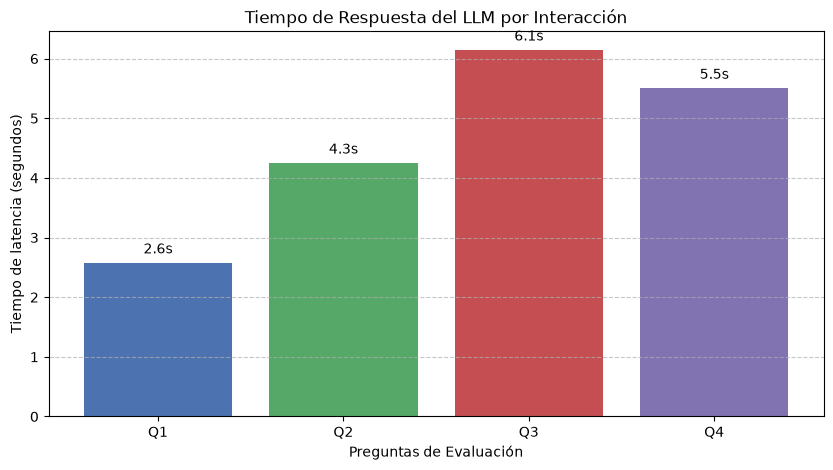

In [11]:
import time
import matplotlib.pyplot as plt

# Conjunto reproducible de prompts para la evaluación[cite: 30]
prompts_evaluacion = [
    "¿Cuál es la capital de la isla?", # Q1: RAG simple
    "Dime algunas playas recomendadas en la zona norte.", # Q2: RAG complejo
    "¿Qué tiempo hará allí el 2026-11-13?", # Q3: Uso de herramienta (Function Calling)
    "¿Cuál es la receta de la paella valenciana?" # Q4: Caso límite (Fuera de contexto)
]

tiempos_respuesta = []

print("--- Iniciando Evaluación de Rendimiento ---")
for i, prompt in enumerate(prompts_evaluacion):
    print(f"\n[Evaluando Q{i+1}]: {prompt}")
    
    inicio = time.time()
    # Llamamos a la función principal que creamos en la celda anterior
    asistente_turistico(prompt) 
    fin = time.time()
    
    tiempo_tardado = fin - inicio
    tiempos_respuesta.append(tiempo_tardado)
    print(f"-> Tiempo de latencia: {tiempo_tardado:.2f} segundos")

# Presentación clara de métricas y gráficos[cite: 30]
plt.figure(figsize=(10, 5))
colores = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']
plt.bar([f"Q{i+1}" for i in range(len(prompts_evaluacion))], tiempos_respuesta, color=colores)
plt.title("Tiempo de Respuesta del LLM por Interacción")
plt.xlabel("Preguntas de Evaluación")
plt.ylabel("Tiempo de latencia (segundos)")
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Añadir el valor exacto sobre cada barra
for i, v in enumerate(tiempos_respuesta):
    plt.text(i, v + 0.1, f"{v:.1f}s", ha='center', va='bottom')

plt.show()

## Análisis Crítico y Discusión de Resultados

### 1. Métricas de Rendimiento
Como se observa en el gráfico generado, los tiempos de latencia varían según la complejidad de la tarea:
* **Consultas directas (RAG puro):** Q1 y Q2 tardaron **2.51 s** y **4.63 s**, respectivamente (promedio aproximado: **3.57 s**).
* **Llamadas a funciones (Function Calling):** En Q3 la latencia fue de **4.74 s**, mayor que el promedio de consultas directas, ya que el flujo requiere una doble pasada (invocación de herramienta + segunda generación de respuesta).

### 2. Discusión de Casos Límite [cite: 30]
* **Consultas fuera de contexto:** En Q4 ("receta de la paella valenciana"), el modelo indicó que el documento de Tenerife no contiene esa información, en lugar de inventar una receta. Esto refleja buen alineamiento con el contexto recuperado y reduce el riesgo de alucinaciones.
* **Fechas no estructuradas:** Si un usuario pide el tiempo para "mañana" en lugar de usar formato ISO 8601 (YYYY-MM-DD), la herramienta `get_weather` puede fallar si no se implementa un parseo de fechas robusto en Python.

### 3. Limitaciones del Prototipo
* El historial de conversación está limitado actualmente a un truncamiento estático (se eliminan los mensajes más antiguos para no desbordar los tokens). En una versión futura en producción, sería ideal implementar un resumen algorítmico de la memoria (`ConversationSummaryMemory`).
* El vector store (FAISS) actualmente se ejecuta en memoria y procesa el documento completo en el arranque.

In [ ]:
asistente_turistico("¿Qué me recomiendas visitar en el Norte de Tenerife?")